Connected to .venv01 (3.13.11) (Python 3.13.11)

In [ ]:
# SEARCH WORDS :
# FINAL_READY_OUTPUTS_BY_YEAR
# YEARLY_TCN_ESTIMATION
# YEARLY_MFIV_GARCH_ESTIMATION
# TESTING_MAIN_WITH_CACHE
# TCN_SCORE_CALIBRATION_DIAGNOSTIC
## TCN_SCORE_THRESHOLD_CALIBRATION
### TCN_SCORE_THRESHOLD_TRADER_CALIBRATION
import pandas as pd
import numpy as np
from math import sqrt, pi, exp
from arch import arch_model
import yfinance as yf 
from scipy.optimize import minimize
import warnings
from arch.__future__ import reindexing
from arch.utility.exceptions import ConvergenceWarning
# from srcA.msGarch import msGARCH
# from srcA.metrics import metrics
# from srcA.msGarch import msGARCHIV
from tqdm import tqdm

from xgboost import XGBRegressor
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="y is poorly scaled")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)


import os, sys
sys.path.insert(0, "/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.path.insert(0, "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/MFIV_calibration")
os.chdir("/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.modules.pop("srcB", None)

### NOTE :
# # COMES FROM MODELLING.ipynb
import pickle 
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_01.pkl", "rb") as f:
    outputs_by_year = pickle.load(f)


# IMPORTS FROM SRC
from srcB.market import *
from srcB.trader_testing import testing_execute_trading_strategy
from srcB.model_testing import regime_switching_mfiv
from srcB.helpers import *

# READ D_BTC AND DF
from pathlib import Path
DATA_DIR = Path("../data/rawData")
YEARS = [2019, 2020, 2021]
d_btc_raw_by_year = {}
df_raw_by_year = {}
for y in YEARS:
    d_btc_raw_by_year[y] = pd.read_parquet(DATA_DIR / f"btc_underlying_minutely_{y}.parquet")
    df_raw_by_year[y]    = pd.read_parquet(DATA_DIR / f"derivative_data_{y}.parquet")

# SET INDEX TO DATETIME
for y in YEARS:
    d_btc_raw_by_year[y] = d_btc_raw_by_year[y].set_index(pd.to_datetime(d_btc_raw_by_year[y]["date_time"]))
    df_raw_by_year[y] = df_raw_by_year[y].set_index(pd.to_datetime(df_raw_by_year[y]["date_time"]))



# ==================================================================================================================
# ======================================= LOAD XQ_BY_YEAR USING X_BY_YEAR ==========================================
# ==================================================================================================================
YEARS = [2019, 2020, 2021]

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/x_by_year_fut/x_by_year.pkl", "rb") as f:
    X_by_year = pd.read_pickle(f)

# X_by_year[2021]["rt"] # CHECKING DELETE
for y in YEARS:
    X_by_year[y] = X_by_year[y].copy()
    X_by_year[y]["rv"] = X_by_year[y]["rt"] ** 2

Xq_by_year = {}
YEARS = [2019, 2020, 2021]
for y in YEARS:
    Xq_by_year[y] = {}
    Xq_by_year[y]["q1"] = X_by_year[y].loc[f"{y}-01-01" : f"{y}-03-31 23:59:59"]
    Xq_by_year[y]["q2"] = X_by_year[y].loc[f"{y}-04-01" : f"{y}-06-30 23:59:59"]
    Xq_by_year[y]["q3"] = X_by_year[y].loc[f"{y}-07-01" : f"{y}-09-30 23:59:59"]
    Xq_by_year[y]["q4"] = X_by_year[y].loc[f"{y}-10-01" : f"{y}-12-31 23:59:59"]

# =============================================================================================================
# ============== MFIV SCALING ============= SCALING ONLY ON XQ  =================================================
# ================== CONVERTS ANNUALIZED MFIV -> CUMULATIVE H-HOUR DECIMAL VARIANCE ===========================

MFIVS = list(range(2, 577))
QUARTERS = ["q1", "q2", "q3", "q4"]

for y in YEARS:
    for q in QUARTERS:
        for H in MFIVS:
            Xq_by_year[y][q][f"MFIV_{H}"] *= (H / 8760.0)

# ==================================================================================================================
# ============================================= BORROW RFR COLUMN  =================================================
# ==================================================================================================================
import pickle
with open ("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/ready_data/d_btc_by_year_all.pkl", "rb") as f :
    d_btc_by_year = pickle.load(f)

YEARS = [2019, 2020, 2021]
for y in YEARS:
    d_btc_raw_by_year[y]["rfr"] = d_btc_by_year[y]["rfr"].reindex(d_btc_raw_by_year[y].index, method="ffill")

# =============================================================================================================
# ======================================= CHECKPOINT 1. RUN UNTIL HERE ========================================
# =============================================================================================================











# # =============================================================================================================
# # ======================================= PREPARE EMPTY DICTS =================================================
# # =============================================================================================================

YEARS = [2019, 2020, 2021]
QUARTERS = ["q1", "q2", "q3", "q4"]

idx_by_year = {y : {} for y in YEARS}
f_rollB_by_year = {y: {} for y in YEARS}
rolling_forecasts =  {y: {} for y in YEARS}
rolling_residuals = {y: {} for y in YEARS}
y_pred_by_year = {y: {} for y in YEARS}
y_true_by_year = {y: {} for y in YEARS}

# # =============================== FIND OPTIMAL PARAMETERS IN hyperparam_tuning.py ==================================
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/hyperparameters/tcn_best_params.pkl", "rb") as f:
    best_tcn_params = pickle.load(f)

# # ======================================= YEARLY_TCN_ESTIMATION  ===================================================
# # ==================================================================================================================
sys.modules.pop("srcB.tcn_model", None)
sys.modules.pop("srcB.tcn_model_v2", None)
from srcB.tcn_model_v2 import *
YEARS = [2019, 2020, 2021]
QUARTERS = ["q1", "q2", "q3", "q4"]
tcn_bundle_by_year = {}
tcn_targets_by_year = {}
tcn_output_by_year = {}

for y in YEARS:
    X_df = pd.concat([Xq_by_year[y][q] for q in QUARTERS]).sort_index().copy()
    garch_df = pd.concat([outputs_by_year[y][q]["garch"] for q in QUARTERS]).sort_index()
    X_df["garch"] = garch_df.reindex(X_df.index)
    # ======= the parameter tuning block should go right here , right ?===========
    tcn_output, tcn_bundle, tcn_targets = tcn_mfiv(
        X_df=X_df,
        option_df=df_raw_by_year[y],
        time_df=d_btc_raw_by_year[y],
        sequence_length=168,
        forward_hours=24,
        delta_target=0.20,
        channels=best_tcn_params["channels"],
        kernel_size=best_tcn_params["kernel_size"],
        dropout=best_tcn_params["dropout"],
        batch_size=best_tcn_params["batch_size"],
        learning_rate=best_tcn_params["learning_rate"],
        weight_decay=best_tcn_params["weight_decay"]
    )
    tcn_output_by_year[y] = tcn_output
    tcn_bundle_by_year[y] = tcn_bundle
    tcn_targets_by_year[y] = tcn_targets

    for q in QUARTERS:
        q_index = Xq_by_year[y][q].index
        tcn_q = tcn_output.reindex(q_index)
        outputs_by_year[y][q] = pd.concat( [outputs_by_year[y][q], tcn_q], axis=1 )

In [ ]:
# =============================================================================================================
# ======================================= SAVE TCN BUNDLES ====================================================
# =============================================================================================================
os.makedirs("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/TCN", exist_ok = True)
import pickle
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/TCN/tcn_bundle_by_year.pkl", "wb") as f:
    pickle.dump(tcn_bundle_by_year, f)

print("TCN bundles saved:", list(tcn_bundle_by_year.keys()))

TCN bundles saved: [2019, 2020, 2021]


In [ ]:
#==================================================================================================================
#======================================= YEARLY_MFIV_GARCH_ESTIMATION  ============================================
#==================================================================================================================
# YEARLY ESTIMATION
YEARS = [2019, 2020, 2021]
QUARTERS = ["q1", "q2", "q3", "q4"]

# THE_COLS = [f"MFIV_{h}" for h in range(2, 577)]
HORIZONS = [12, 24, 72, 168, 336]
THE_COLS = [f"MFIV_{h}" for h in HORIZONS]

for y in YEARS:
    X_df = pd.concat([Xq_by_year[y][q] for q in QUARTERS]).sort_index()
    f_rollB, y_true, idx, regime_state, selected_horizon = regime_switching_mfiv(
        X_df,
        THE_COLS,
        score_window=168
    )
    full_forecast = pd.Series(f_rollB, index=X_df.index[idx])
    full_true = pd.Series(y_true, index=X_df.index[idx])
    full_regime = pd.Series(regime_state, index=X_df.index[idx])
    full_horizon = pd.Series(selected_horizon, index=X_df.index[idx])
    for q in QUARTERS:
        q_index = Xq_by_year[y][q].index
        f_q = full_forecast.reindex(q_index).dropna()
        y_q = full_true.reindex(f_q.index)
        regime_q = full_regime.reindex(f_q.index)
        horizon_q = full_horizon.reindex(f_q.index)
        idx_q = Xq_by_year[y][q].index.get_indexer(f_q.index)
        idx_by_year[y][q] = idx_q
        f_rollB_by_year[y][q] = f_q.to_numpy()
        rolling_forecasts[y][q] = f_q.to_numpy()
        rolling_residuals[y][q] = (y_q - f_q).to_numpy()
        y_pred_by_year[y][q] = f_q.to_numpy()
        y_true_by_year[y][q] = y_q.to_numpy()
        outputs_by_year[y][q] = pd.concat([outputs_by_year[y][q], pd.DataFrame({"regime_switching_mfiv": f_q, "regime_state": regime_q, "selected_horizon" : horizon_q})], axis = 1)

In [ ]:
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_04.pkl", "wb") as f:
    pickle.dump(outputs_by_year, f)

In [ ]:
# ==================================== BORROW MFIV COLS FROM XQ_BY_YEAR ================================
# ===========================================================================================================

MFIVS = list(range(2, 577))
QUARTERS = ["q1", "q2", "q3", "q4"]
mfiv_cols = [f"MFIV_{H}" for H in MFIVS]

for y in YEARS:
    for q in QUARTERS:
        outputs_by_year[y][q].drop(columns=mfiv_cols, inplace=True)

for y in YEARS:
    for q in QUARTERS:
        outputs_by_year[y][q] = pd.concat(
            [outputs_by_year[y][q], Xq_by_year[y][q][mfiv_cols]],
            axis=1
        )

In [ ]:
# # IMPORTS FROM SRC
from srcB.market import *
from srcB.trader_testing import testing_execute_trading_strategy
from srcB.helpers import *

In [ ]:
# ==================================================================================================================
# ======================================= CACHE FOR WARMUP ==========================================================
# ==================================================================================================================
CACHE_YEARS = [2019, 2020, 2021]
RUN_BY = "year"
if RUN_BY == "year":
    trader_cache = {
        y: pd.concat(
            [
                outputs_by_year[yy][q]
                for yy in CACHE_YEARS
                if yy <= y
                for q in QUARTERS
            ]
        ).sort_index()
        for y in CACHE_YEARS
    }

elif RUN_BY == "quarter":
    trader_cache = {
        (y, q): pd.concat(
            [
                outputs_by_year[yy][qq]
                for yy in CACHE_YEARS
                for qq in QUARTERS
                if (
                    yy < y
                    or (yy == y and QUARTERS.index(qq) <= QUARTERS.index(q))
                )
            ]
        ).sort_index()
        for y in CACHE_YEARS
        for q in QUARTERS
    }
if RUN_BY == "year":
    PERIODS = YEARS
else:
    PERIODS = [(y, q) for y in YEARS for q in QUARTERS]

In [ ]:
# ==================================================================================================================
# ======================================= TESTING_MAIN_WITH_CACHE  ==========================================================
# ==================================================================================================================
# sys.modules.pop("srcB", None)

sys.modules.pop("srcB.trader_testing_tcn", None)
from srcB.trader_testing_tcn import testing_execute_trading_strategy
YEARS = [2019, 2020, 2021]
MODELS = [
    "garch",
    "garch_n_mfiv",
    "tcn_mfiv"
]
RUN_BY = "year"
strategy_results = {}
for YEAR in YEARS:
    for MODEL in MODELS:
        market = Market(
            option_df=df_raw_by_year[YEAR],
            time_df=d_btc_raw_by_year[YEAR],
            starting_cash=100_000,
            im_multiplier=0.15,
            mm_buffer_rate=0.05,
        )
        greek_tests = []
        yearly_snapshots = []
        if RUN_BY == "year":
            periods = [None]
        else:
            periods = ["q1", "q2", "q3", "q4"]
            
        for q in periods:
            snapshots, greek_tests_q = testing_execute_trading_strategy(
                bt_year=YEAR,
                bt_quarter=q,
                model=MODEL,
                outputs_by_year=outputs_by_year,
                market=market,
                trader_cache=trader_cache,
                run_by=RUN_BY,
                quantity=10,
                expiry_days=30,
                hold_days=7,
                lookback_hours=168,
                mean_hours=12,
                ql=0.10,
                qh=0.90,
                z=1.645
            )

            greek_tests.extend(greek_tests_q)
            yearly_snapshots.extend(snapshots)
        history_key = f"{MODEL}_{str(YEAR)[2:]}"
        equity_curve = market.get_equity_history()
        strategy_results[history_key] = {
            "equity_curve": equity_curve,
            "snapshots": yearly_snapshots,
            "greek_tests": greek_tests,
            "orders": list(market.orders),
            "transactions": list(market.transactions),
            "final_cash": market.cash,
            "required_margin": market.get_total_required_margin(),
            "free_liquidity": market.get_free_liquidity(),
        }
print(YEAR, MODEL)

2021 tcn_mfiv


In [ ]:
# ==================================================================================================================
# ============================================= SAVE DICT  ========================================================
# ==================================================================================================================
import sys, os
os.makedirs("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/data_strategy_results", exist_ok = True)
import pickle 
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/data_strategy_results/strategy_results.pkl", "wb") as f:
    pickle.dump(strategy_results, f)

In [ ]:
## ==================================================================================================================
## ============================================= SHARPEE  ===========================================================
## ==================================================================================================================
YEARS = [2019, 2020, 2021]
MODELS = [
    "garch",
    "garch_n_mfiv",
    "tcn_mfiv"
]
rows = []

for y in YEARS:
    for model in MODELS:

        history_key = f"{model}_{str(y)[2:]}"
        snapshots = strategy_results[history_key]["snapshots"]

        equity = pd.Series( [s["equity"] for s in snapshots], index=[s["time"] for s in snapshots] )

        returns = equity.pct_change().dropna()
        sharpe = returns.mean() / returns.std() * np.sqrt(24 * 365)

        rows.append({ "year": y, "model": model, "sharpe": sharpe })

sharpe_table = pd.DataFrame(rows)

print(sharpe_table)

   year         model    sharpe
0  2019         garch -0.116801
1  2019  garch_n_mfiv -0.765328
2  2019      tcn_mfiv  0.464297
3  2020         garch  0.319238
4  2020  garch_n_mfiv -0.198904
5  2020      tcn_mfiv  0.907050
6  2021         garch  0.057619
7  2021  garch_n_mfiv  0.100386
8  2021      tcn_mfiv  1.097422


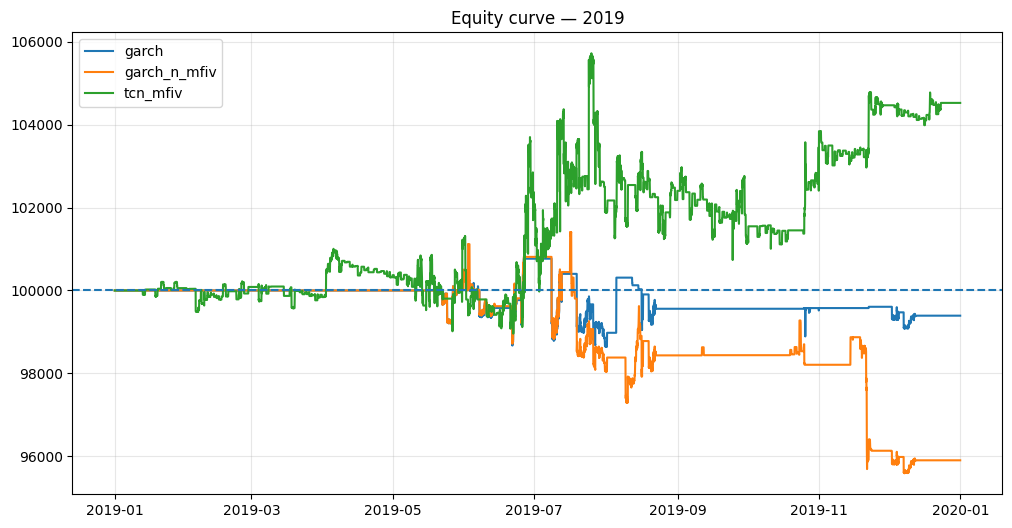

In [ ]:
# ==================================================================================================================
# ============================================= PLOT EQUITY  =======================================================
# ==================================================================================================================
import matplotlib.pyplot as plt
# MODELS = ["garch", "garch_mfiv", "garch_n_mfiv", "garch_mfiv_avg", "regime_switching_mfiv"]
MODELS = [
    "garch",
    "garch_n_mfiv",
    "tcn_mfiv"
]
PLOT_YEAR = 2019
plt.figure(figsize=(12, 6))
for MODEL in MODELS:
    plot_key = f"{MODEL}_{str(PLOT_YEAR)[2:]}"
    result = strategy_results[plot_key]
    eq = pd.DataFrame(result["snapshots"]).drop_duplicates("time").sort_values("time")
    plt.plot(eq["time"], eq["equity"], label=MODEL)
plt.axhline(100_000, linestyle="--")
plt.title(f"Equity curve — {PLOT_YEAR}")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [ ]:
## =============================================================================================================
## ============================== TCN FITTED TARGET-SPACE PERFORMANCE ==========================================
## =============================================================================================================

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]
rows = []
for y in YEARS:
    test = pd.concat([
        tcn_output_by_year[y][["tcn_action"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort = False).dropna()
    realized = pd.Series(0.0, index=test.index)
    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        mask = test["tcn_action"] == action
        realized.loc[mask] = test.loc[mask, f"target_{action}"]
    sharpe = realized.mean() / realized.std()
    rows.append({
        "year": y,
        "n": len(realized),
        "mean_target": realized.mean(),
        "target_sharpe": sharpe,
        "profitable": (realized > 0).mean()
    })
target_sharpe = pd.DataFrame(rows)
print(target_sharpe)

   year     n  mean_target  target_sharpe  profitable
0  2019  2194     0.001857       0.089180    0.204193
1  2020  4093     0.003348       0.124975    0.331786
2  2021  5008     0.005096       0.212137    0.513179


In [ ]:
# =============================================================================================================
# =========================== TCN TARGET PERFORMANCE: EXECUTED VS SKIPPED =====================================
# =============================================================================================================

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]
rows = []
for y in YEARS:
    test = pd.concat([
        tcn_output_by_year[y][["tcn_action"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()
    test = test[test["tcn_action"] != "no_trade"].copy()
    test["target_pnl"] = 0.0
    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["tcn_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]
    entries = tcn_trades[tcn_trades["year"] == y][["entry", "side"]].copy()
    entries["entry"] = pd.to_datetime(entries["entry"], utc=True).dt.floor("h")
    executed = test[test.index.isin(entries["entry"])]
    skipped = test[~test.index.isin(entries["entry"])]
    action_at_entry = test["tcn_action"].reindex(entries["entry"]).to_numpy()
    action_match = (action_at_entry == entries["side"].to_numpy()).mean()
    rows.append({
        "year": y,
        "signals": len(test),
        "executed": len(executed),
        "execution_rate": len(executed) / len(test),
        "action_match": action_match,
        "all_sharpe": test["target_pnl"].mean() / test["target_pnl"].std(),
        "executed_sharpe": executed["target_pnl"].mean() / executed["target_pnl"].std(),
        "skipped_sharpe": skipped["target_pnl"].mean() / skipped["target_pnl"].std()
    })
execution_check = pd.DataFrame(rows)
print(execution_check)

NameError: name 'tcn_trades' is not defined

In [ ]:
# =========================== REQUIRES STRATEGY_RESULTS =======================================================
# =========================== TCN TARGET PERFORMANCE: EXECUTED VS SKIPPED =====================================
# =============================================================================================================

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]

rows = []

for y in YEARS:

    test = pd.concat([
        tcn_output_by_year[y][["tcn_action"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    test = test[test["tcn_action"] != "no_trade"].copy()

    test["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["tcn_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]

    entries = pd.DataFrame(
        strategy_results[f"tcn_mfiv_{str(y)[2:]}"]["greek_tests"]
    )

    entries["time"] = pd.to_datetime(entries["time"], utc=True).dt.floor("h")
    entries = entries.drop_duplicates("time")

    covered = entries[entries["time"].isin(test.index)].copy()

    predicted = test["tcn_action"].reindex(covered["time"]).to_numpy()
    action_match = (predicted == covered["tcn_action"].to_numpy()).mean()

    executed = test[test.index.isin(covered["time"])]
    skipped = test[~test.index.isin(covered["time"])]

    rows.append({
        "year": y,
        "signals": len(test),
        "successful_entries": len(entries),
        "entries_with_target": len(covered),
        "target_coverage": len(covered) / len(entries),
        "action_match": action_match,
        "all_sharpe": test["target_pnl"].mean() / test["target_pnl"].std(),
        "executed_sharpe": executed["target_pnl"].mean() / executed["target_pnl"].std(),
        "skipped_sharpe": skipped["target_pnl"].mean() / skipped["target_pnl"].std()
    })

execution_check = pd.DataFrame(rows)

print(execution_check)

: 

In [ ]:
# ============================= TCN_SCORE_CALIBRATION_DIAGNOSTIC ========================================
# =============================================================================================================
rows = []
for y in YEARS:
    test = pd.concat([
        tcn_output_by_year[y][["tcn_action", "tcn_best_score"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    test = test[test["tcn_action"] != "no_trade"].copy()
    test["target_pnl"] = 0.0
    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["tcn_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]
        
    test["score_bin"] = pd.qcut(
        test["tcn_best_score"],
        5,
        labels=False,
        duplicates="drop"
    )

    x = (
        test.groupby("score_bin")
        .agg(
            n=("target_pnl", "size"),
            mean_score=("tcn_best_score", "mean"),
            mean_target=("target_pnl", "mean"),
            sharpe=("target_pnl", lambda z: z.mean() / z.std()),
            profitable=("target_pnl", lambda z: (z > 0).mean())
        )
        .reset_index()
    )

    x["year"] = y
    rows.append(x)

score_check = pd.concat(rows, ignore_index=True)

print(score_check[[
    "year", "score_bin", "n", "mean_score",
    "mean_target", "sharpe", "profitable"
]].to_string(index=False))

: 

In [ ]:
# =============================================================================================================
# ================================= TCN_SCORE_THRESHOLD_CALIBRATION ===========================================
# =============================================================================================================

tests = {}

for y in YEARS:

    x = pd.concat([
        tcn_output_by_year[y][["tcn_action", "tcn_best_score"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    x = x[x["tcn_action"] != "no_trade"].copy()
    x["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = x["tcn_action"] == action
        x.loc[m, "target_pnl"] = x.loc[m, f"target_{action}"]

    tests[y] = x


scores_all = pd.concat([tests[y]["tcn_best_score"] for y in YEARS])

rows = []

for q in [0, .20, .40, .50, .60, .70, .80, .85, .90]:

    threshold = scores_all.quantile(q)

    for y in YEARS:

        x = tests[y][tests[y]["tcn_best_score"] >= threshold]
        sharpe = x["target_pnl"].mean() / x["target_pnl"].std()

        rows.append({
            "quantile": q,
            "threshold": threshold,
            "year": y,
            "n": len(x),
            "mean_target": x["target_pnl"].mean(),
            "sharpe": sharpe
        })

threshold_check = pd.DataFrame(rows)

print(threshold_check.to_string(index=False))

: 

In [ ]:
# ================================ TCN_SCORE_THRESHOLD_TRADER_CALIBRATION =====================================
# =============================================================================================================

sys.modules.pop("srcB.trader_testing_tcn", None)
from srcB.trader_testing_tcn import testing_execute_trading_strategy

THRESHOLDS = [0.0, 0.003, 0.0074, 0.0090, 0.0117]

rows = []

for threshold in THRESHOLDS:
    for y in YEARS:

        market = Market(
            option_df=df_raw_by_year[y],
            time_df=d_btc_raw_by_year[y],
            starting_cash=100_000,
            im_multiplier=0.15,
            mm_buffer_rate=0.05,
        )

        snapshots, greek_tests = testing_execute_trading_strategy(
            bt_year=y,
            bt_quarter=None,
            model="tcn_mfiv",
            outputs_by_year=outputs_by_year,
            market=market,
            trader_cache=trader_cache,
            run_by="year",
            tcn_score_threshold=threshold
        )

        equity = pd.Series(
            [s["equity"] for s in snapshots],
            index=[s["time"] for s in snapshots]
        )

        returns = equity.pct_change().dropna()
        sharpe = returns.mean() / returns.std() * np.sqrt(24 * 365)

        rows.append({
            "threshold": threshold,
            "year": y,
            "trades": len(greek_tests),
            "sharpe": sharpe
        })

threshold_trader_check = pd.DataFrame(rows)

print(threshold_trader_check.to_string(index=False))

: 

In [ ]:
target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]
rows = []
for y in YEARS:
    test = pd.concat([
        tcn_output_by_year[y][["tcn_action"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort = False).dropna()
    realized = pd.Series(0.0, index=test.index)
    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        mask = test["tcn_action"] == action
        realized.loc[mask] = test.loc[mask, f"target_{action}"]
    sharpe = realized.mean() / realized.std()
    rows.append({
        "year": y,
        "n": len(realized),
        "mean_target": realized.mean(),
        "target_sharpe": sharpe,
        "profitable": (realized > 0).mean()
    })
target_sharpe = pd.DataFrame(rows)
print(target_sharpe)

   year     n  mean_target  target_sharpe  profitable
0  2019  2194     0.001857       0.089180    0.204193
1  2020  4093     0.003348       0.124975    0.331786
2  2021  5008     0.005096       0.212137    0.513179


In [ ]:
# =============================================================================================================
# =========================== TCN TARGET PERFORMANCE: EXECUTED VS SKIPPED =====================================
# =============================================================================================================

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]
rows = []
for y in YEARS:
    test = pd.concat([
        tcn_output_by_year[y][["tcn_action"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()
    test = test[test["tcn_action"] != "no_trade"].copy()
    test["target_pnl"] = 0.0
    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["tcn_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]
    entries = tcn_trades[tcn_trades["year"] == y][["entry", "side"]].copy()
    entries["entry"] = pd.to_datetime(entries["entry"], utc=True).dt.floor("h")
    executed = test[test.index.isin(entries["entry"])]
    skipped = test[~test.index.isin(entries["entry"])]
    action_at_entry = test["tcn_action"].reindex(entries["entry"]).to_numpy()
    action_match = (action_at_entry == entries["side"].to_numpy()).mean()
    rows.append({
        "year": y,
        "signals": len(test),
        "executed": len(executed),
        "execution_rate": len(executed) / len(test),
        "action_match": action_match,
        "all_sharpe": test["target_pnl"].mean() / test["target_pnl"].std(),
        "executed_sharpe": executed["target_pnl"].mean() / executed["target_pnl"].std(),
        "skipped_sharpe": skipped["target_pnl"].mean() / skipped["target_pnl"].std()
    })
execution_check = pd.DataFrame(rows)
print(execution_check)

NameError: name 'tcn_trades' is not defined

In [ ]:
MODEL = "tcn_mfiv"
all_trades = []
for y in YEARS:
    tx = pd.DataFrame(strategy_results[f"{MODEL}_{str(y)[2:]}"]["transactions"]).sort_values("time")

    open_actions = {"buy_to_open", "sell_to_open"}
    close_actions = {"buy_to_close", "sell_to_close", "liquidate", "expiry_settlement"}

    trades = []
    open_pos = {}

    for _, r in tx.iterrows():
        sym = r["symbol"]
        if r["action"] in open_actions:
            open_pos[sym] = {
                "entry_time": r["time"],
                "right": r["right"],
                "strike": r["strike"],
                "direction": r["held_direction"],
                "pnl": float(r["cash_change"])
            }

        elif r["action"] in close_actions and sym in open_pos:
            open_pos[sym]["pnl"] += float(r["cash_change"])
            open_pos[sym]["exit_time"] = r["time"]
            trades.append({
                "symbol": sym,
                **open_pos.pop(sym)
            })

    legs = pd.DataFrame(trades)
    for entry_time, g in legs.groupby("entry_time"):
        direction = "short" if (g["direction"] == "sell").all() else "long"
        structure = "straddle" if g["strike"].nunique() == 1 else "strangle"
        side = f"{direction}_{structure}"
        call_pnl = g.loc[g["right"] == "C", "pnl"].sum()
        put_pnl = g.loc[g["right"] == "P", "pnl"].sum()
        total_pnl = call_pnl + put_pnl

        all_trades.append({
            "year": y,
            "entry": entry_time,
            "exit": g["exit_time"].max(),
            "side": side,
            "call_pnl": call_pnl,
            "put_pnl": put_pnl,
            "total_pnl": total_pnl,
            "position_result": "PROFIT" if total_pnl > 0 else "LOSS"
        })

tcn_trades = pd.DataFrame(all_trades)
print(tcn_trades.to_string(index=False))

summary = (
    tcn_trades.groupby(["year", "side"])
    .agg(
        positions=("total_pnl", "size"),
        profitable=("total_pnl", lambda x: (x > 0).sum()),
        losing=("total_pnl", lambda x: (x < 0).sum()),
        total_pnl=("total_pnl", "sum"),
        avg_pnl=("total_pnl", "mean")
    )
    .reset_index()
)
print("\nSUMMARY")
print(summary.to_string(index=False))

 year                     entry                      exit           side     call_pnl      put_pnl    total_pnl position_result
 2019 2019-01-13 02:00:00+00:00 2019-01-14 15:00:00+00:00  long_strangle    -5.039077    29.227890    24.188812          PROFIT
 2019 2019-01-18 12:00:00+00:00 2019-01-19 14:00:00+00:00  long_straddle    71.555610   -53.146955    18.408655          PROFIT
 2019 2019-01-21 00:00:00+00:00 2019-01-22 06:00:00+00:00 short_straddle    12.525765    10.253285    22.779050          PROFIT
 2019 2019-01-22 07:00:00+00:00 2019-01-25 00:00:00+00:00  long_strangle    -3.684740    -1.978263    -5.663002            LOSS
 2019 2019-01-25 07:00:00+00:00 2019-01-26 07:00:00+00:00  long_strangle    -6.778830    -2.445761    -9.224591            LOSS
 2019 2019-01-26 17:00:00+00:00 2019-01-28 00:00:00+00:00 short_straddle    21.519445   -10.576930    10.942515          PROFIT
 2019 2019-01-28 01:00:00+00:00 2019-02-01 00:00:00+00:00  long_strangle    -1.985478    -1.985318    -3

In [ ]:
target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]
rows = []
for y in YEARS:
    test = pd.concat([
        tcn_output_by_year[y][["tcn_action"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort = False).dropna()
    realized = pd.Series(0.0, index=test.index)
    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        mask = test["tcn_action"] == action
        realized.loc[mask] = test.loc[mask, f"target_{action}"]
    sharpe = realized.mean() / realized.std()
    rows.append({
        "year": y,
        "n": len(realized),
        "mean_target": realized.mean(),
        "target_sharpe": sharpe,
        "profitable": (realized > 0).mean()
    })
target_sharpe = pd.DataFrame(rows)
print(target_sharpe)
# =============================================================================================================
# =========================== TCN TARGET PERFORMANCE: EXECUTED VS SKIPPED =====================================
# =============================================================================================================

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]
rows = []
for y in YEARS:
    test = pd.concat([
        tcn_output_by_year[y][["tcn_action"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()
    test = test[test["tcn_action"] != "no_trade"].copy()
    test["target_pnl"] = 0.0
    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["tcn_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]
    entries = tcn_trades[tcn_trades["year"] == y][["entry", "side"]].copy()
    entries["entry"] = pd.to_datetime(entries["entry"], utc=True).dt.floor("h")
    executed = test[test.index.isin(entries["entry"])]
    skipped = test[~test.index.isin(entries["entry"])]
    action_at_entry = test["tcn_action"].reindex(entries["entry"]).to_numpy()
    action_match = (action_at_entry == entries["side"].to_numpy()).mean()
    rows.append({
        "year": y,
        "signals": len(test),
        "executed": len(executed),
        "execution_rate": len(executed) / len(test),
        "action_match": action_match,
        "all_sharpe": test["target_pnl"].mean() / test["target_pnl"].std(),
        "executed_sharpe": executed["target_pnl"].mean() / executed["target_pnl"].std(),
        "skipped_sharpe": skipped["target_pnl"].mean() / skipped["target_pnl"].std()
    })
execution_check = pd.DataFrame(rows)
print(execution_check)


# =========================== REQUIRES STRATEGY_RESULTS =======================================================
# =========================== TCN TARGET PERFORMANCE: EXECUTED VS SKIPPED =====================================
# =============================================================================================================

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]

rows = []

for y in YEARS:

    test = pd.concat([
        tcn_output_by_year[y][["tcn_action"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    test = test[test["tcn_action"] != "no_trade"].copy()

    test["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["tcn_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]

    entries = pd.DataFrame(
        strategy_results[f"tcn_mfiv_{str(y)[2:]}"]["greek_tests"]
    )

    entries["time"] = pd.to_datetime(entries["time"], utc=True).dt.floor("h")
    entries = entries.drop_duplicates("time")

    covered = entries[entries["time"].isin(test.index)].copy()

    predicted = test["tcn_action"].reindex(covered["time"]).to_numpy()
    action_match = (predicted == covered["tcn_action"].to_numpy()).mean()

    executed = test[test.index.isin(covered["time"])]
    skipped = test[~test.index.isin(covered["time"])]

    rows.append({
        "year": y,
        "signals": len(test),
        "successful_entries": len(entries),
        "entries_with_target": len(covered),
        "target_coverage": len(covered) / len(entries),
        "action_match": action_match,
        "all_sharpe": test["target_pnl"].mean() / test["target_pnl"].std(),
        "executed_sharpe": executed["target_pnl"].mean() / executed["target_pnl"].std(),
        "skipped_sharpe": skipped["target_pnl"].mean() / skipped["target_pnl"].std()
    })

execution_check = pd.DataFrame(rows)

print(execution_check)

   year     n  mean_target  target_sharpe  profitable
0  2019  2194     0.001857       0.089180    0.204193
1  2020  4093     0.003348       0.124975    0.331786
2  2021  5008     0.005096       0.212137    0.513179
   year  signals  executed  execution_rate  action_match  all_sharpe  \
0  2019      987        79        0.080041      0.448864    0.133577   
1  2020     2622       138        0.052632      0.589744    0.156823   
2  2021     4067       189        0.046472      0.707865    0.236633   

   executed_sharpe  skipped_sharpe  
0         0.290540        0.121597  
1         0.081269        0.160412  
2         0.197196        0.238411  
   year  signals  successful_entries  entries_with_target  target_coverage  \
0  2019      987                 176                   79         0.448864   
1  2020     2622                 234                  138         0.589744   
2  2021     4067                 267                  189         0.707865   

   action_match  all_sharpe  execu

In [ ]:
# =============================================================================================================
# ============================= TCN_SCORE_CALIBRATION_DIAGNOSTIC ========================================
# =============================================================================================================
rows = []
for y in YEARS:
    test = pd.concat([
        tcn_output_by_year[y][["tcn_action", "tcn_best_score"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    test = test[test["tcn_action"] != "no_trade"].copy()
    test["target_pnl"] = 0.0
    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["tcn_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]
        
    test["score_bin"] = pd.qcut(
        test["tcn_best_score"],
        5,
        labels=False,
        duplicates="drop"
    )

    x = (
        test.groupby("score_bin")
        .agg(
            n=("target_pnl", "size"),
            mean_score=("tcn_best_score", "mean"),
            mean_target=("target_pnl", "mean"),
            sharpe=("target_pnl", lambda z: z.mean() / z.std()),
            profitable=("target_pnl", lambda z: (z > 0).mean())
        )
        .reset_index()
    )

    x["year"] = y
    rows.append(x)

score_check = pd.concat(rows, ignore_index=True)

print(score_check[[
    "year", "score_bin", "n", "mean_score",
    "mean_target", "sharpe", "profitable"
]].to_string(index=False))

 year  score_bin   n  mean_score  mean_target    sharpe  profitable
 2019          0 198    0.000232     0.001069  0.067932    0.378788
 2019          1 197    0.000770     0.003015  0.088302    0.426396
 2019          2 197    0.001543     0.004104  0.134794    0.446701
 2019          3 197    0.002879     0.002260  0.078303    0.477157
 2019          4 198    0.008842     0.010180  0.256761    0.540404
 2020          0 525    0.000401    -0.001323 -0.071556    0.411429
 2020          1 524    0.001413     0.001515  0.072655    0.446565
 2020          2 524    0.002964     0.001709  0.088423    0.511450
 2020          3 524    0.005550     0.004391  0.207470    0.580153
 2020          4 525    0.020825     0.019827  0.326953    0.640000
 2021          0 814    0.000598     0.000547  0.028810    0.568796
 2021          1 813    0.001846     0.002334  0.113532    0.606396
 2021          2 813    0.003376     0.004422  0.209975    0.632226
 2021          3 813    0.006013     0.005081  0

In [ ]:
# =============================================================================================================
# ================================= TCN_SCORE_THRESHOLD_CALIBRATION ===========================================
# =============================================================================================================

tests = {}

for y in YEARS:

    x = pd.concat([
        tcn_output_by_year[y][["tcn_action", "tcn_best_score"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    x = x[x["tcn_action"] != "no_trade"].copy()
    x["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = x["tcn_action"] == action
        x.loc[m, "target_pnl"] = x.loc[m, f"target_{action}"]

    tests[y] = x


scores_all = pd.concat([tests[y]["tcn_best_score"] for y in YEARS])

rows = []

for q in [0, .20, .40, .50, .60, .70, .80, .85, .90]:

    threshold = scores_all.quantile(q)

    for y in YEARS:

        x = tests[y][tests[y]["tcn_best_score"] >= threshold]
        sharpe = x["target_pnl"].mean() / x["target_pnl"].std()

        rows.append({
            "quantile": q,
            "threshold": threshold,
            "year": y,
            "n": len(x),
            "mean_target": x["target_pnl"].mean(),
            "sharpe": sharpe
        })

threshold_check = pd.DataFrame(rows)

print(threshold_check.to_string(index=False))

 quantile    threshold  year    n  mean_target   sharpe
     0.00 2.729066e-07  2019  987     0.004129 0.133577
     0.00 2.729066e-07  2020 2622     0.005227 0.156823
     0.00 2.729066e-07  2021 4067     0.006275 0.236633
     0.20 9.158482e-04  2019  641     0.005148 0.156454
     0.20 9.158482e-04  2020 2056     0.007063 0.195245
     0.20 9.158482e-04  2021 3444     0.007296 0.265604
     0.40 2.128435e-03  2019  372     0.006755 0.189291
     0.40 2.128435e-03  2020 1560     0.008688 0.218945
     0.40 2.128435e-03  2021 2674     0.008842 0.301655
     0.50 2.910593e-03  2019  291     0.007632 0.202475
     0.50 2.910593e-03  2020 1309     0.009805 0.231497
     0.50 2.910593e-03  2021 2238     0.010088 0.330455
     0.60 3.921284e-03  2019  206     0.009424 0.238753
     0.60 3.921284e-03  2020 1075     0.011808 0.258799
     0.60 3.921284e-03  2021 1790     0.011238 0.348108
     0.70 5.362298e-03  2019  137     0.012450 0.282635
     0.70 5.362298e-03  2020  806     0.014763 0

In [ ]:
# =============================================================================================================
# ================================ TCN_SCORE_THRESHOLD_TRADER_CALIBRATION =====================================
# =============================================================================================================

sys.modules.pop("srcB.trader_testing_tcn", None)
from srcB.trader_testing_tcn import testing_execute_trading_strategy

THRESHOLDS = [0.0, 0.003, 0.0074, 0.0090, 0.0117]

rows = []

for threshold in THRESHOLDS:
    for y in YEARS:

        market = Market(
            option_df=df_raw_by_year[y],
            time_df=d_btc_raw_by_year[y],
            starting_cash=100_000,
            im_multiplier=0.15,
            mm_buffer_rate=0.05,
        )

        snapshots, greek_tests = testing_execute_trading_strategy(
            bt_year=y,
            bt_quarter=None,
            model="tcn_mfiv",
            outputs_by_year=outputs_by_year,
            market=market,
            trader_cache=trader_cache,
            run_by="year",
            tcn_score_threshold=threshold
        )

        equity = pd.Series(
            [s["equity"] for s in snapshots],
            index=[s["time"] for s in snapshots]
        )

        returns = equity.pct_change().dropna()
        sharpe = returns.mean() / returns.std() * np.sqrt(24 * 365)

        rows.append({
            "threshold": threshold,
            "year": y,
            "trades": len(greek_tests),
            "sharpe": sharpe
        })

threshold_trader_check = pd.DataFrame(rows)

print(threshold_trader_check.to_string(index=False))

 threshold  year  trades    sharpe
    0.0000  2019     176  0.464297
    0.0000  2020     234  0.907050
    0.0000  2021     267  1.097422
    0.0030  2019      70  0.231125
    0.0030  2020     154  0.977293
    0.0030  2021     215  1.232548
    0.0074  2019      28  1.152804
    0.0074  2020      77  1.212196
    0.0074  2021     100  1.261123
    0.0090  2019      17 -0.067066
    0.0090  2020      61  1.534654
    0.0090  2021      81  1.471073
    0.0117  2019      14  0.117518
    0.0117  2020      46  1.224447
    0.0117  2021      52  1.824181
